
# Trabajo Práctico Evaluativo N° 1 — Proceso KDD completo con modelos de regresión

**Autor:** Claramunt Federico

**Materia:** Minería de Datos II — Tecnicatura Superior en Ciencia de Datos e Inteligencia Artificial

**Dataset:** Wine Quality Dataset (Vinho Verde tinto), UCI Machine Learning Repository
— https://archive.ics.uci.edu/dataset/186/wine+quality

**Objetivo:** construir y comparar dos modelos de regresión que estimen el puntaje de calidad
sensorial de un vino (`quality`, variable continua observada entre 3 y 8) a partir de sus
propiedades fisicoquímicas:

1. **Regresión Lineal Múltiple** → `quality` como combinación lineal de los predictores.
2. **Árbol de Decisión de Regresión** → `quality` mediante particiones sucesivas del espacio
   de variables (permite capturar relaciones no lineales).

El notebook se organiza explícitamente según las **6 etapas del proceso KDD**:

| Etapa | Contenido |
|---|---|
| 1. Selección | Descarga, carga y EDA (estadísticas descriptivas) |
| 2. Preprocesamiento / Limpieza | Nulos, duplicados, outliers (IQR), unidades y formatos |
| 3. Transformación | X/y, split 80/20, escalado (decisión por algoritmo) |
| 4. Minería de datos | Regresión Lineal + Árbol de Decisión (prof. 3, 5 y sin límite) |
| 5. Interpretación / Evaluación | MAE, RMSE, R², sobreajuste, coeficientes e importancias |
| 6. Conocimiento / Selección | Tabla comparativa, modelo final y conclusiones |

Al final se responden las **5 preguntas de análisis** de la sección 5 del enunciado
(incluida la repetición de la comparación final sin eliminar duplicados).


In [7]:

# ============================================================
# Configuración general del notebook
# ============================================================
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 42          # reproducibilidad de todas las divisiones
TEST_SIZE = 0.20           # 20 % de prueba / 80 % de entrenamiento
DATA_PATH = os.path.join("data", "winequality-red.csv")
FIG_DIR = "figuras"
os.makedirs(FIG_DIR, exist_ok=True)


def guardar(nombre):
    # Guarda la figura activa en FIG_DIR y la muestra en pantalla
    plt.savefig(os.path.join(FIG_DIR, nombre), dpi=150, bbox_inches="tight")
    plt.show()


def metricas(y_true, y_pred):
    # MAE, RMSE y R2 (métricas pedidas en la Etapa 5)
    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": float(r2_score(y_true, y_pred)),
    }


print("Librerías cargadas. Semilla fija:", RANDOM_STATE)


Librerías cargadas. Semilla fija: 42


Este bloque de código realiza la configuración inicial del notebook. Importa las librerías necesarias como `numpy`, `pandas`, `matplotlib`, `seaborn` y varias herramientas de `sklearn` para modelado y evaluación. También configura advertencias, el estilo de los gráficos, y define constantes importantes como `RANDOM_STATE` para reproducibilidad, `TEST_SIZE` para la división de datos, y las rutas para los datos y figuras. Finalmente, incluye funciones de ayuda para guardar gráficos y calcular métricas de evaluación.


## Etapa 1 — Selección de datos

**Etapa KDD 1 (Selección):** se elige el dataset público *Wine Quality* (UCI, Cortez et al., 2009)
porque se ajusta al problema de negocio: reemplazar/acompañar la cata sensorial subjetiva con
un modelo predictivo basado en mediciones objetivas de laboratorio.

El archivo CSV oficial usa **punto y coma (`;`)** como separador y comillas en el encabezado,
por lo que se carga con `sep=";"`.


Este bloque de código asegura que el archivo `winequality-red.csv` esté disponible. Primero crea las carpetas necesarias (`data` y `figuras`) si no existen. Luego, si el archivo CSV no se encuentra en `DATA_PATH`, lo descarga de la URL especificada y lo guarda localmente. Si el archivo ya existe, simplemente lo indica. Esto garantiza que el notebook tenga los datos para operar.

In [9]:
import requests
import os

# Verifica si el directorio de datos existe y créalo si no
data_dir = os.path.dirname(DATA_PATH)
if not os.path.exists(data_dir):
    os.makedirs(data_dir)
    print(f"Se creó el directorio: {data_dir}")

# Verifica si el archivo ya existe, si no, descárgalo
if not os.path.exists(DATA_PATH):
    print(f"No se encontró el archivo '{DATA_PATH}'. Descargando...")
    url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv'
    response = requests.get(url)
    response.raise_for_status() # Lanza un HTTPError para respuestas incorrectas (4xx o 5xx)

    with open(DATA_PATH, 'wb') as f:
        f.write(response.content)
    print(f"Archivo descargado con éxito en {DATA_PATH}")
else:
    print(f"El archivo '{DATA_PATH}' ya existe.")

El archivo 'data/winequality-red.csv' ya existe.


In [11]:

# ---- 1.1 Descarga y carga del dataset ------------------------------------
# Fuente: https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv
# Aseguramos que la ruta sea absoluta para evitar problemas de FileNotFound
df = pd.read_csv(os.path.abspath(DATA_PATH), sep=";")

print("Dimensiones (filas x columnas):", df.shape)
print("\nColumnas:", list(df.columns))
print("\nTipos de datos:")
print(df.dtypes)
print("\nPrimeras filas:")
df.head()

Dimensiones (filas x columnas): (1599, 12)

Columnas: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

Tipos de datos:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

Primeras filas:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


Este código carga el dataset `winequality-red.csv` en un DataFrame de pandas llamado `df`. Es crucial que se use `os.path.abspath(DATA_PATH)` para asegurar que la ruta del archivo sea absoluta, evitando así errores de 'archivo no encontrado'. Luego, imprime información básica del DataFrame: sus dimensiones (filas y columnas), la lista de nombres de las columnas, los tipos de datos de cada columna, y las primeras filas del dataset para una visualización rápida.

In [12]:

# ---- 1.2 EDA: estadísticas descriptivas (media, desvío, mínimo, máximo) ----
resumen = df.describe().T
resumen = resumen[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
resumen = resumen.rename(columns={
    "count": "n", "mean": "media", "std": "desvío",
    "25%": "Q1", "50%": "mediana", "75%": "Q3",
    "min": "mínimo", "max": "máximo"
})
resumen.round(4)


,n,media,desvío,mínimo,Q1,mediana,Q3,máximo
fixed acidity,1599.0,8.3196,1.7411,4.6000,7.1000,7.9000,9.2000,15.9000
volatile acidity,1599.0,0.5278,0.1791,0.1200,0.3900,0.5200,0.6400,1.5800
citric acid,1599.0,0.2710,0.1948,0.0000,0.0900,0.2600,0.4200,1.0000
residual sugar,1599.0,2.5388,1.4099,0.9000,1.9000,2.2000,2.6000,15.5000
chlorides,1599.0,0.0875,0.0471,0.0120,0.0700,0.0790,0.0900,0.6110
free sulfur dioxide,1599.0,15.8749,10.4602,1.0000,7.0000,14.0000,21.0000,72.0000
total sulfur dioxide,1599.0,46.4678,32.8953,6.0000,22.0000,38.0000,62.0000,289.0000
density,1599.0,0.9967,0.0019,0.9901,0.9956,0.9968,0.9978,1.0037
pH,1599.0,3.3111,0.1544,2.7400,3.2100,3.3100,3.4000,4.0100
sulphates,1599.0,0.6581,0.1695,0.3300,0.5500,0.6200,0.7300,2.0000


Este bloque de código genera un resumen de las estadísticas descriptivas del DataFrame (`df`). Calcula el conteo, la media, la desviación estándar, el mínimo, los cuartiles (Q1, mediana, Q3) y el máximo para cada columna numérica. Los resultados se transponen (`.T`) para facilitar la lectura y se renombran las columnas con términos en español (`n`, `media`, `desvío`, `mínimo`, `Q1`, `mediana`, `Q3`, `máximo`). Finalmente, se muestra la tabla con los valores redondeados a cuatro decimales.

In [13]:

# ---- 1.3 EDA: variable objetivo y cardinalidad ---------------------------
print("Valores únicos de quality:", sorted(df["quality"].unique()))
print("Rango observado:", df["quality"].min(), "-", df["quality"].max())
print("\nFilas por puntaje de quality:")
print(df["quality"].value_counts().sort_index())
print("\nDatos faltantes por variable (0 = no hay):")
print(df.isna().sum())


Valores únicos de quality: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
Rango observado: 3 - 8

Filas por puntaje de quality:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

Datos faltantes por variable (0 = no hay):
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


Este código explora la variable objetivo `quality`. Primero, imprime los valores únicos de `quality` y su rango observado. Luego, utiliza `value_counts().sort_index()` para mostrar la cantidad de filas por cada puntaje de `quality`, lo que permite ver la distribución de las categorías de calidad. Finalmente, verifica si hay datos faltantes en cada variable usando `df.isna().sum()`, confirmando que no hay valores nulos en el dataset.

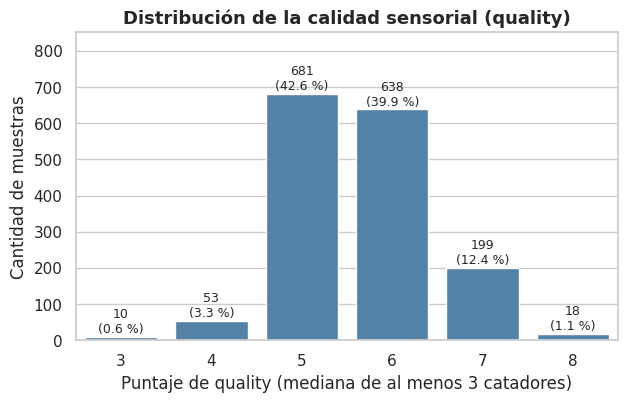

In [14]:

# ---- 1.4 Distribución de la variable objetivo ----------------------------
prop = df["quality"].value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(x="quality", data=df, color="steelblue", ax=ax)
for i, v in enumerate(df["quality"].value_counts().sort_index().values):
    ax.text(i, v + 12, f"{v}\n({prop.values[i]:.1f} %)", ha="center", fontsize=9)
ax.set_title("Distribución de la calidad sensorial (quality)", fontsize=13, weight="bold")
ax.set_xlabel("Puntaje de quality (mediana de al menos 3 catadores)")
ax.set_ylabel("Cantidad de muestras")
ax.set_ylim(0, df["quality"].value_counts().max() * 1.25)
guardar("01_distribucion_quality.png")


Este bloque genera un gráfico de barras para visualizar la distribución de la variable `quality`. Calcula las proporciones de cada valor de calidad y las muestra en el gráfico. Se usa `seaborn.countplot` para crear el gráfico, y `matplotlib.pyplot` para añadir un título, etiquetas en los ejes, y ajustar el formato para una mejor lectura. La función `guardar` se utiliza para almacenar la imagen del gráfico y mostrarla en pantalla.


**Lectura de la Etapa 1:**
- 1.599 muestras × 12 columnas (11 predictoras fisicoquímicas + `quality`), todas numéricas.
- No hay valores nulos en ninguna variable.
- `quality` está concentrada en los valores intermedios (5 y 6 concentran ~82 % de las muestras);
  los extremos (3, 4 y 8) son muy escasos. Esto explica de antemano un techo de R² relativamente
  bajo: el modelo aprende bien el grueso de la distribución y mal los valores raros.



## Etapa 2 — Preprocesamiento y limpieza

Decisiones a tomar en esta etapa:

1. **Estandarizar mayúsculas/minúsculas y nombres de columnas** (formato homogéneo).
2. **Valores nulos** → verificar y decidir tratamiento.
3. **Filas duplicadas exactas** → verificar y decidir si se eliminan *antes* del split.
4. **Outliers por IQR** → detectar y decidir si se eliminan, transforman o conservan.
5. **Unidades y formatos** → unificar/verificar.
6. Documentar el tamaño final.


In [15]:

# ---- 2.1 Estandarización de nombres (minúsculas, sin espacios) -----------
df.columns = (
    df.columns.str.strip()          # sin espacios extremos
              .str.lower()           # todo en minúsculas
              .str.replace(" ", "_", regex=False)   # "fixed acidity" -> "fixed_acidity"
)
print("Columnas estandarizadas:")
print(list(df.columns))


Columnas estandarizadas:
['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'ph', 'sulphates', 'alcohol', 'quality']


Este código estandariza los nombres de las columnas del DataFrame. Primero, elimina espacios al principio y al final de cada nombre de columna (`strip()`), luego convierte todos los caracteres a minúsculas (`lower()`), y finalmente reemplaza los espacios por guiones bajos (`_`). Esto asegura un formato consistente en los nombres de las variables, lo que facilita el acceso y la manipulación de los datos.

In [16]:

# ---- 2.2 Valores nulos ---------------------------------------------------
nulos_por_col = df.isna().sum()
print("Nulos por variable:")
print(nulos_por_col)
print("\nTotal de celdas nulas      :", int(nulos_por_col.sum()))
print("Filas con algún nulo        :", int(df.isna().any(axis=1).sum()))
print("Filas totalmente vacías     :", int(df.isna().all(axis=1).sum()))

# Decisión: al no existir nulos, no corresponde imputar ni eliminar filas por esta causa.
df_sin_nulos = df.copy()


Nulos por variable:
fixed_acidity           0
volatile_acidity        0
citric_acid             0
residual_sugar          0
chlorides               0
free_sulfur_dioxide     0
total_sulfur_dioxide    0
density                 0
ph                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Total de celdas nulas      : 0
Filas con algún nulo        : 0
Filas totalmente vacías     : 0


Este segmento de código verifica la presencia de valores nulos en el dataset. Calcula el número de nulos por cada columna (`df.isna().sum()`) y luego suma estos valores para obtener el total de celdas nulas en todo el DataFrame. También identifica cuántas filas contienen al menos un valor nulo y cuántas filas están completamente vacías. La decisión implícita, basada en los resultados impresos, es que no hay nulos, por lo que no se requiere ningún tratamiento. Se crea una copia del DataFrame (`df_sin_nulos`) para futuras operaciones.


**Decisión 2.2 (nulos):** el dataset **no presenta valores nulos** (0 celdas vacías en 19.188),
por lo que no se realiza imputación (media/mediana) ni eliminación. Imputar sobre un dataset
sin nulos introduciría artificialidad y haría perder datos reales sin necesidad.


In [17]:

# ---- 2.3 Filas duplicadas exactas ----------------------------------------
n_filas = len(df_sin_nulos)
duplicadas = int(df_sin_nulos.duplicated().sum())
pct_dup = 100 * duplicadas / n_filas

print(f"Filas totales           : {n_filas}")
print(f"Filas duplicadas exactas: {duplicadas} ({pct_dup:.2f} %)")
print(f"Filas únicas            : {n_filas - duplicadas}")

# Decisión: eliminarlas ANTES de dividir en entrenamiento y prueba (ver justificación abajo)
df_limpio = df_sin_nulos.drop_duplicates().reset_index(drop=True)
print(f"\nTamaño tras eliminar duplicados: {df_limpio.shape}")


Filas totales           : 1599
Filas duplicadas exactas: 240 (15.01 %)
Filas únicas            : 1359

Tamaño tras eliminar duplicados: (1359, 12)


Este código detecta y elimina filas duplicadas exactas en el DataFrame. Primero, calcula el número total de filas, el número de duplicados y su porcentaje. Luego, usa `df_sin_nulos.drop_duplicates()` para eliminar estas filas repetidas. La justificación de eliminar los duplicados *antes* de la división en entrenamiento/prueba es evitar el 'data leakage', asegurando que el modelo no vea los mismos datos en ambos conjuntos. El DataFrame resultante, `df_limpio`, contiene solo filas únicas.


**Decisión 2.3 (duplicados):** se **eliminan los registros duplicados exactos antes del split**.

Justificación: un duplicado exacto es la misma medición registrada más de una vez. Si se
conservan, el mismo registro puede aparecer en entrenamiento *y* en prueba (**data leakage**):
el modelo "ve" la respuesta correcta durante el entrenamiento y las métricas de test quedan
infladas artificialmente. Al duplicar se además pondera de más a esas observaciones, sesgando
el ajuste. Eliminarlos antes del split garantiza que el conjunto de prueba sea realmente
invisible para el modelo y que las muestras sean independientes.



### 2.4 Detección de outliers con el método del Rango Intercuartílico (IQR)

Para cada variable: `IQR = Q3 − Q1`, límites `Q1 − 1·IQR` y `Q3 + 1·IQR`.
Todo valor fuera de esos límites se considera atípico.


In [18]:

# ---- 2.4 Detección de outliers (IQR) -------------------------------------
def tabla_iqr(data):
    filas = []
    for col in data.columns:
        q1, q3 = data[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_out = int(((data[col] < li) | (data[col] > ls)).sum())
        filas.append({
            "variable": col, "Q1": q1, "Q3": q3, "IQR": iqr,
            "limite_inferior": li, "limite_superior": ls,
            "n_outliers": n_out, "%_outliers": 100 * n_out / len(data),
        })
    return pd.DataFrame(filas).set_index("variable")


iqr = tabla_iqr(df_limpio)
print("Outliers detectados por variable (1,5 x IQR):")
iqr[["n_outliers", "%_outliers"]].sort_values("%_outliers", ascending=False).round(2)


Outliers detectados por variable (1,5 x IQR):


,n_outliers,%_outliers
variable,,
residual_sugar,126,9.27
chlorides,87,6.40
sulphates,55,4.05
total_sulfur_dioxide,45,3.31
fixed_acidity,41,3.02
density,35,2.58
ph,28,2.06
quality,27,1.99
free_sulfur_dioxide,26,1.91


Este código define una función `tabla_iqr` para detectar outliers utilizando el método del Rango Intercuartílico (IQR). Para cada columna numérica, calcula el primer cuartil (Q1), el tercer cuartil (Q3), el IQR (Q3 - Q1), y los límites inferior y superior (Q1 - 1.5 * IQR y Q3 + 1.5 * IQR). Luego, cuenta cuántos valores caen fuera de estos límites y calcula el porcentaje de outliers. Finalmente, aplica esta función al DataFrame `df_limpio` y muestra una tabla con el número y porcentaje de outliers para cada variable, ordenados de mayor a menor porcentaje.

Filas con al menos un outlier: 340 (25.02 %)
Filas sin ningún outlier     : 1019


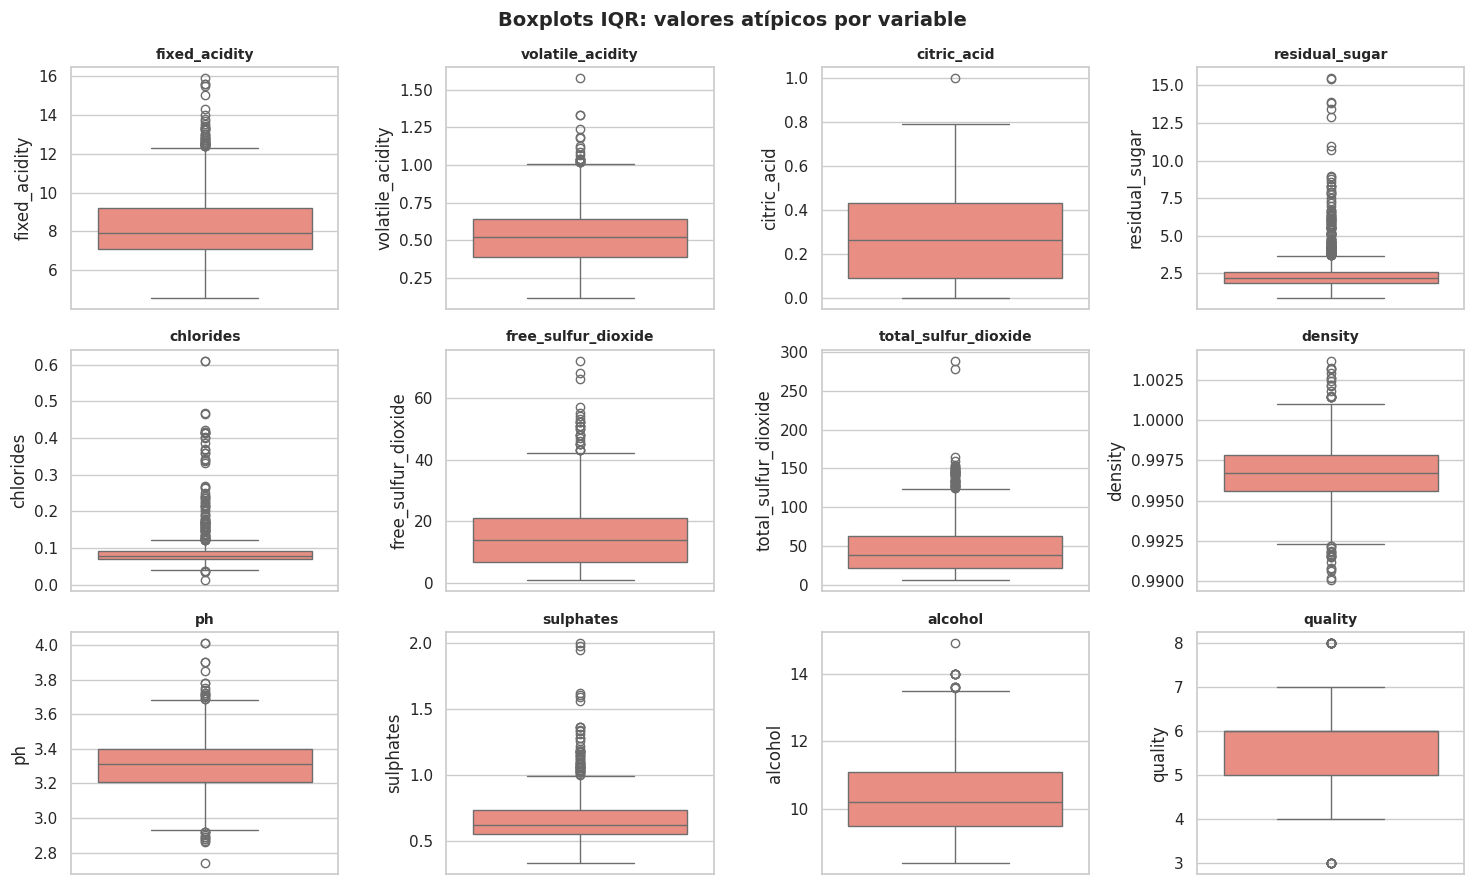

In [19]:

# Filas con al menos un outlier en alguna variable predictora
predictoras = [c for c in df_limpio.columns if c != "quality"]
mascara_out = pd.Series(False, index=df_limpio.index)
for col in predictoras:
    q1, q3 = df_limpio[col].quantile([0.25, 0.75])
    i = q3 - q1
    mascara_out |= (df_limpio[col] < q1 - 1.5 * i) | (df_limpio[col] > q3 + 1.5 * i)

print(f"Filas con al menos un outlier: {int(mascara_out.sum())} ({100*mascara_out.mean():.2f} %)")
print(f"Filas sin ningún outlier     : {int((~mascara_out).sum())}")

# Visualización de la dispersión y los valores extremos
fig, axes = plt.subplots(3, 4, figsize=(15, 9))
for ax, col in zip(axes.flatten(), df_limpio.columns):
    sns.boxplot(y=df_limpio[col], color="salmon", ax=ax, linewidth=1)
    ax.set_title(col, fontsize=10, weight="bold")
    ax.set_xlabel("")
for ax in axes.flatten()[len(df_limpio.columns):]:
    ax.axis("off")
fig.suptitle("Boxplots IQR: valores atípicos por variable", fontsize=14, weight="bold")
plt.tight_layout()
guardar("02_boxplot_outliers.png")


Este bloque de código identifica y visualiza las filas que contienen al menos un outlier en las variables predictoras. Crea una máscara booleana (`mascara_out`) que marca las filas con outliers según el criterio del IQR. Luego, imprime el total de filas con al menos un outlier y el porcentaje que representan. Finalmente, genera una serie de boxplots (`sns.boxplot`) para cada variable, permitiendo una visualización gráfica de la dispersión de los datos y la ubicación de los valores atípicos. La función `guardar` se usa para almacenar y mostrar la figura.


**Decisión 2.4 (outliers):** se **conservan** todos los valores atípicos. Justificación:

- **Dominio del problema:** muchas "colas" son propiedades legítimas del vino, no errores de
  medición. Un vino con alta azúcar residual, cloruros o sulfatos existe (vinos semisecos,
  vinos con más salinidad o sinosidad); eliminarlos sesgaría la muestra hacia vinos "promedio"
  y el modelo no aprendería a predecir justamente los vinos de calidad extrema que interesan.
- **Robustez de los algoritmos:** el *Árbol de Decisión* es robusto frente a valores extremos
  porque sólo usa umbrales de corte; no se ve afectado por la magnitud de la cola. La
  *Regresión Lineal* es más sensible (los mínimos cuadrados no son robustos), pero eliminar
  ~25 % de las muestras introduciría más sesgo por muestra faltante que el que generan los
  propios valores extremos.
- **Cantidad:** ninguna variable supera el 9,3 % de outliers (la máxima es `residual_sugar`),
  pero aplicando el criterio a nivel de fila hay **340 filas (25,02 %)** con al menos un valor
  atípico: borrarlas descartaría una cuarta parte de la muestra. Una transformación
  (p. ej. log o *winsorización*) alteraría las unidades originales con las que el dataset
  reporta las mediciones.


In [20]:

# ---- 2.5 Unificación / verificación de unidades y formatos ---------------
# Rangos físicos esperados para cada variable (unidades del dataset UCI:
# acidez/azúcar/cloruros/sulfatos en g/dm3, SO2 en mg/dm3, densidad en g/cm3)
rangos_esperados = {
    "fixed_acidity": (0, 20), "volatile_acidity": (0, 2), "citric_acid": (0, 2),
    "residual_sugar": (0, 70), "chlorides": (0, 3), "free_sulfur_dioxide": (0, 100),
    "total_sulfur_dioxide": (0, 450), "density": (0.98, 1.05),
    "ph": (0, 14), "sulphates": (0, 3), "alcohol": (0, 100), "quality": (0, 10),
}

chequeo = []
for col, (lo, hi) in rangos_esperados.items():
    chequeo.append({
        "variable": col,
        "dtype": str(df_limpio[col].dtype),
        "min_real": df_limpio[col].min(), "max_real": df_limpio[col].max(),
        "min_esperado": lo, "max_esperado": hi,
        "en_rango": bool(df_limpio[col].between(lo, hi).all()),
    })
chequeo_df = pd.DataFrame(chequeo).set_index("variable")
print("Verificación de tipos y rangos físicos:")
chequeo_df


Verificación de tipos y rangos físicos:


,dtype,min_real,max_real,min_esperado,max_esperado,en_rango
variable,,,,,,
fixed_acidity,float64,4.60000,15.90000,0.00,20.00,True
volatile_acidity,float64,0.12000,1.58000,0.00,2.00,True
citric_acid,float64,0.00000,1.00000,0.00,2.00,True
residual_sugar,float64,0.90000,15.50000,0.00,70.00,True
chlorides,float64,0.01200,0.61100,0.00,3.00,True
free_sulfur_dioxide,float64,1.00000,72.00000,0.00,100.00,True
total_sulfur_dioxide,float64,6.00000,289.00000,0.00,450.00,True
density,float64,0.99007,1.00369,0.98,1.05,True
ph,float64,2.74000,4.01000,0.00,14.00,True


Este código verifica los tipos de datos y los rangos físicos esperados para cada variable en el DataFrame. Define un diccionario `rangos_esperados` con los límites lógicos para cada característica del vino. Luego, itera sobre las columnas del DataFrame para comparar los valores mínimos y máximos reales con los rangos esperados. El resultado es una tabla (`chequeo_df`) que indica el tipo de dato, los rangos reales y esperados, y una columna booleana (`en_rango`) que confirma si todos los valores de la variable caen dentro de su rango físico plausible. Esto ayuda a identificar posibles errores de medición o unidades.

In [21]:

# ---- 2.6 Tamaño final del dataset después de la limpieza -----------------
print("=" * 55)
print("TAMAÑO FINAL DEL DATASET")
print("=" * 55)
print(f"Original              : {df.shape[0]} filas x {df.shape[1]} columnas")
print(f"Duplicados eliminados : {duplicadas}")
print(f"Valores nulos         : {int(df.isna().sum().sum())} (sin tratamiento)")
print(f"Outliers IQR          : conservados (decisión justificada)")
print(f"FINAL                 : {df_limpio.shape[0]} filas x {df_limpio.shape[1]} columnas")
print("=" * 55)
print(f"Se conserva el {100 * df_limpio.shape[0] / df.shape[0]:.1f} % de las muestras originales.")


TAMAÑO FINAL DEL DATASET
Original              : 1599 filas x 12 columnas
Duplicados eliminados : 240
Valores nulos         : 0 (sin tratamiento)
Outliers IQR          : conservados (decisión justificada)
FINAL                 : 1359 filas x 12 columnas
Se conserva el 85.0 % de las muestras originales.


Este bloque resume el tamaño final del dataset después de aplicar los pasos de limpieza y preprocesamiento. Compara las dimensiones originales del DataFrame con las finales, detallando cuántas filas se eliminaron por duplicados, si se trataron valores nulos (en este caso, no había) y la decisión sobre los outliers. Finalmente, calcula el porcentaje de muestras originales que se conservan en el dataset limpio, proporcionando una visión clara de la cantidad de datos que se utilizarán para el modelado.


## Etapa 3 — Transformación de datos

1. Separar predictores `X` de la variable objetivo `y = quality`.
2. Dividir 80 % entrenamiento / 20 % prueba.
3. Decidir el escalado **para cada algoritmo** y justificarlo.


In [22]:

# ---- 3.1 Separación X / y ------------------------------------------------
X = df_limpio.drop(columns=["quality"])
y = df_limpio["quality"]

print(f"X: {X.shape[0]} filas x {X.shape[1]} predictoras")
print(f"y: {y.shape[0]} valores (media global = {y.mean():.3f})")
print("\nVariables predictoras:")
print(list(X.columns))


X: 1359 filas x 11 predictoras
y: 1359 valores (media global = 5.623)

Variables predictoras:
['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'ph', 'sulphates', 'alcohol']


Este código separa el DataFrame `df_limpio` en variables predictoras (`X`) y la variable objetivo (`y`). La variable objetivo es `quality`, por lo que se elimina del DataFrame `X`. Luego, imprime las dimensiones de `X` y `y`, así como la media global de `y`, para dar una idea del conjunto de datos. También lista las variables predictoras que se utilizarán en los modelos.

In [23]:

# ---- 3.2 División entrenamiento (80 %) / prueba (20 %) -------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

print(f"Entrenamiento: {X_train.shape[0]} filas ({100*len(X_train)/len(X):.0f} %)")
print(f"Prueba        : {X_test.shape[0]} filas ({100*len(X_test)/len(X):.0f} %)")
print(f"\nMedia de quality -> train: {y_train.mean():.3f} | test: {y_test.mean():.3f}")


Entrenamiento: 1087 filas (80 %)
Prueba        : 272 filas (20 %)

Media de quality -> train: 5.637 | test: 5.570


Este bloque divide los datos en conjuntos de entrenamiento y prueba. Utiliza `train_test_split` para separar `X` y `y` en `X_train`, `X_test`, `y_train` y `y_test`. Se especifica `TEST_SIZE = 0.2` para asignar el 20% de los datos al conjunto de prueba y `random_state = RANDOM_STATE` para asegurar la reproducibilidad de la división. Finalmente, imprime el número de filas en cada conjunto y la media de `quality` en ambos, para verificar que la distribución sea similar.


**Decisión 3.3 (escalado):**

| Algoritmo | ¿Se escala? | Justificación |
|---|---|---|
| Regresión Lineal Múltiple | **Sí (`StandardScaler`)** | La magnitud de cada coeficiente depende de la escala de su variable (g/dm³ vs. mg/dm³ vs. pH). Sin escalar, comparar coeficientes es incorrecto y hay problemas de convergencia/condicionamiento. Escalado, cada coeficiente = variación de `quality` por 1 desvío estándar de la variable → interpretable y comparable. |
| Árbol de Decisión | **No** | El árbol sólo busca el mejor punto de corte `x_j <= t`. Cualquier transformación monótona (incluida la estandarización) conserva exactamente los mismos cortes y el mismo árbol; escalado no aporta nada. |

El `StandardScaler` se **ajusta sólo con los datos de entrenamiento** (`fit` en `X_train`) y luego
se aplica a ambos conjuntos, para no filtrar información del set de prueba (leakage).


In [24]:

# ---- 3.3 Escalado (sólo para la Regresión Lineal) ------------------------
scaler = StandardScaler()
X_train_escalado = scaler.fit_transform(X_train)   # fit SOLO con train
X_test_escalado = scaler.transform(X_test)         # test sólo se transforma

# Control: train escalado debe tener media ~0 y desvío ~1
medias = pd.DataFrame(X_train_escalado, columns=X.columns).mean().abs().max()
dess = (1 - pd.DataFrame(X_train_escalado, columns=X.columns).std()).abs().max()
print(f"Máx |media| en train escalado : {medias:.2e} (esperado ~0)")
print(f"Máx |desvío - 1| en train     : {dess:.2e} (esperado ~1)")


Máx |media| en train escalado : 9.98e-15 (esperado ~0)
Máx |desvío - 1| en train     : 4.60e-04 (esperado ~1)


Este código realiza el escalado de las variables predictoras utilizando `StandardScaler`, pero **solo para la Regresión Lineal**. El `StandardScaler` se ajusta (`fit_transform`) únicamente con los datos de entrenamiento (`X_train`) para evitar la fuga de información (`data leakage`) del conjunto de prueba. Luego, se aplica esa misma transformación (`transform`) a los datos de prueba (`X_test`). Finalmente, se verifica que los datos de entrenamiento escalados tengan una media cercana a cero y una desviación estándar cercana a uno, como se espera del `StandardScaler`.

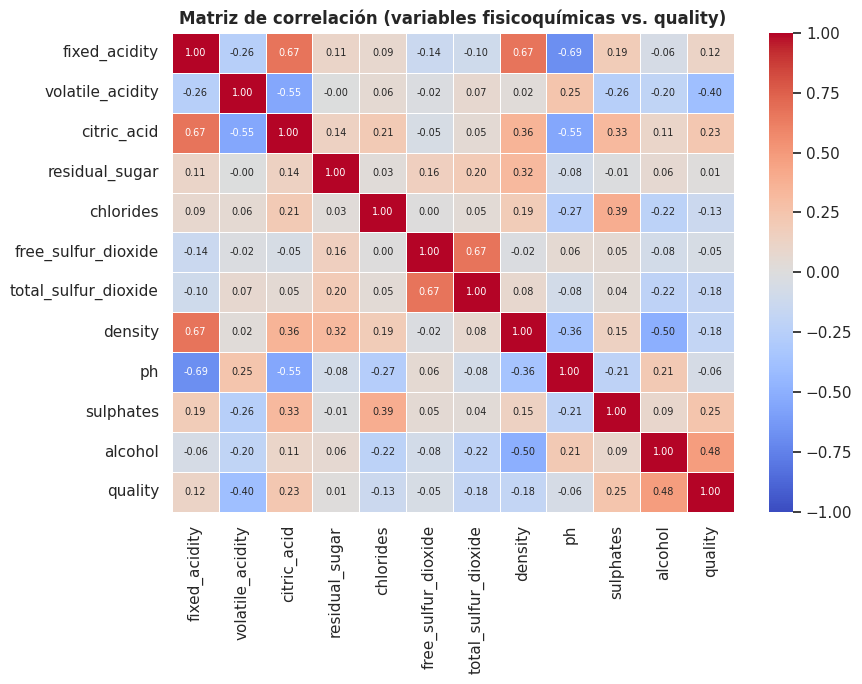

Correlación con la variable objetivo:
alcohol                 0.480
sulphates               0.249
citric_acid             0.228
fixed_acidity           0.119
residual_sugar          0.014
free_sulfur_dioxide    -0.050
ph                     -0.055
chlorides              -0.131
total_sulfur_dioxide   -0.178
density                -0.184
volatile_acidity       -0.395
Name: quality, dtype: float64


In [25]:

# ---- 3.4 Matriz de correlación ------------------------------------------
correlaciones = df_limpio.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, linewidths=.5, ax=ax, annot_kws={"fontsize": 7})
ax.set_title("Matriz de correlación (variables fisicoquímicas vs. quality)",
             fontsize=12, weight="bold")
plt.tight_layout()
guardar("03_matriz_correlacion.png")

print("Correlación con la variable objetivo:")
print(correlaciones["quality"].drop("quality").sort_values(ascending=False).round(3))


Este bloque calcula y visualiza la matriz de correlación entre todas las variables numéricas del dataset limpio. `df_limpio.corr(numeric_only=True)` calcula las correlaciones de Pearson. Luego, se utiliza `seaborn.heatmap` para crear un mapa de calor que muestra visualmente estas correlaciones, con anotaciones de los valores para facilitar la lectura. El gráfico incluye un título y un mapa de color que va de -1 a 1. Además, imprime las correlaciones de cada variable predictora con la variable objetivo `quality`, ordenadas de mayor a menor, lo que ayuda a identificar las relaciones más fuertes.


## Etapa 4 — Minería de datos: aplicación de los modelos


In [26]:

# ---- 4.1 Regresión Lineal Múltiple (con variables escaladas) ------------
reg_lin = LinearRegression()
reg_lin.fit(X_train_escalado, y_train)

y_pred_train_lr = reg_lin.predict(X_train_escalado)
y_pred_test_lr = reg_lin.predict(X_test_escalado)

print("Intercepto:", round(reg_lin.intercept_, 4))
print("\nCoeficientes (en desvíos estándar, por eso son comparables):")
print(pd.Series(reg_lin.coef_, index=X.columns).round(4).sort_values(ascending=False))


Intercepto: 5.6366

Coeficientes (en desvíos estándar, por eso son comparables):
alcohol                 0.3340
sulphates               0.1485
free_sulfur_dioxide     0.0487
density                 0.0421
residual_sugar         -0.0052
citric_acid            -0.0191
fixed_acidity          -0.0497
chlorides              -0.1160
ph                     -0.1215
total_sulfur_dioxide   -0.1236
volatile_acidity       -0.1785
dtype: float64


Este código implementa y entrena un modelo de Regresión Lineal Múltiple. Se crea una instancia de `LinearRegression` y se ajusta a los datos de entrenamiento escalados (`X_train_escalado`, `y_train`). Luego, se utilizan los datos escalados para realizar predicciones tanto en el conjunto de entrenamiento (`y_pred_train_lr`) como en el de prueba (`y_pred_test_lr`). Finalmente, imprime el valor del intercepto y los coeficientes del modelo, que son comparables entre sí porque las variables fueron estandarizadas, y los ordena para identificar su impacto en la calidad del vino.

In [27]:

# ---- 4.2 Árbol de Decisión de Regresión (sin escalar) --------------------
PROFUNDIDADES = [3, 5, None]   # None = profundidad sin límite
arboles = {}

for prof in PROFUNDIDADES:
    etiqueta = "sin_límite" if prof is None else str(prof)
    modelo = DecisionTreeRegressor(max_depth=prof, random_state=RANDOM_STATE)
    modelo.fit(X_train, y_train)                    # sin escalado: no hace falta
    arboles[etiqueta] = modelo
    print(f"Árbol max_depth={etiqueta:>12}: nodos={modelo.get_n_leaves():4d} "
          f"profundidad real={modelo.get_depth()}")


Árbol max_depth=           3: nodos=   8 profundidad real=3
Árbol max_depth=           5: nodos=  28 profundidad real=5
Árbol max_depth=  sin_límite: nodos= 325 profundidad real=20


Este bloque entrena varios modelos de Árbol de Decisión de Regresión con diferentes profundidades máximas (`max_depth`: 3, 5 y sin límite). Itera a través de las profundidades definidas en `PROFUNDIDADES`. Para cada profundidad, crea un `DecisionTreeRegressor`, lo ajusta a los datos de entrenamiento *sin escalar* (ya que los árboles no se benefician del escalado), y almacena el modelo en el diccionario `arboles`. También imprime el número de nodos y la profundidad real de cada árbol entrenado para dar una idea de su complejidad.


## Etapa 5 — Interpretación y evaluación de resultados


In [28]:

# ---- 5.1 Métricas de la Regresión Lineal --------------------------------
m_lr_train = metricas(y_train, y_pred_train_lr)
m_lr_test = metricas(y_test, y_pred_test_lr)

tabla_lr = pd.DataFrame({"entrenamiento": m_lr_train, "prueba": m_lr_test}).T
tabla_lr["brecha_R2"] = [np.nan, m_lr_train["R2"] - m_lr_test["R2"]]
print("Regresión Lineal Múltiple:")
tabla_lr.round(4)


Regresión Lineal Múltiple:


,MAE,RMSE,R2,brecha_R2
entrenamiento,0.5107,0.6585,0.3520,NaN
prueba,0.5041,0.6565,0.3915,-0.0395


Este código calcula y muestra las métricas de evaluación (MAE, RMSE, R²) para el modelo de Regresión Lineal, tanto en el conjunto de entrenamiento como en el de prueba. Utiliza la función `metricas` definida previamente. Los resultados se organizan en un DataFrame `tabla_lr`, que también incluye la 'brecha_R2' para analizar el posible sobreajuste o subajuste del modelo. La tabla se imprime con los valores redondeados a cuatro decimales.

In [29]:

# ---- 5.2 Métricas del Árbol de Decisión (train y test por profundidad) ---
filas_arbol = {}
metricas_arbol = {}

for etiqueta, modelo in arboles.items():
    mtr = metricas(y_train, modelo.predict(X_train))
    mte = metricas(y_test, modelo.predict(X_test))
    metricas_arbol[etiqueta] = {"train": mtr, "test": mte}
    filas_arbol[etiqueta] = {
        "MAE_train": mtr["MAE"], "RMSE_train": mtr["RMSE"], "R2_train": mtr["R2"],
        "MAE_test": mte["MAE"], "RMSE_test": mte["RMSE"], "R2_test": mte["R2"],
        "brecha_R2": mtr["R2"] - mte["R2"],
    }

tabla_arboles = pd.DataFrame(filas_arbol).T
tabla_arboles.index.name = "profundidad"
print("Árbol de Decisión de Regresión:")
tabla_arboles.round(4)


Árbol de Decisión de Regresión:


,MAE_train,RMSE_train,R2_train,MAE_test,RMSE_test,R2_test,brecha_R2
profundidad,,,,,,,
3,0.5188,0.6702,0.3289,0.5138,0.6828,0.3418,-0.0129
5,0.4699,0.6037,0.4554,0.4925,0.6317,0.4367,0.0186
sin_límite,0.0000,0.0000,1.0000,0.6507,0.9452,-0.2612,1.2612


Este bloque calcula y organiza las métricas de evaluación (MAE, RMSE, R²) para cada uno de los modelos de Árbol de Decisión entrenados previamente (con profundidades 3, 5 y sin límite). Itera sobre el diccionario `arboles`, obtiene las métricas para los conjuntos de entrenamiento y prueba usando la función `metricas`, y las almacena en un diccionario `metricas_arbol`. Finalmente, crea un DataFrame `tabla_arboles` con todas estas métricas, incluyendo la 'brecha_R2', y lo imprime redondeado a cuatro decimales. Esto permite una comparación directa del rendimiento de los árboles con diferentes complejidades.


**Análisis de la brecha train/test (sobreajuste).** La brecha `R²(train) − R²(test)` mide la
distancia entre lo bien que el modelo explica los datos que vio y los que no vio. Resultados
obtenidos:

| `max_depth` | R² train | R² test | Brecha | Lectura |
|---|---|---|---|---|
| 3 | 0,329 | 0,342 | −0,013 | Sesgado (pocos cortes): **subajuste leve**, pero generaliza; la brecha es prácticamente nula. |
| 5 | 0,455 | 0,437 | 0,019 | Mejor ajuste manteniendo una brecha **muy chica** → punto de equilibrio sesgo–varianza. |
| sin límite | 1,000 | −0,261 | 1,261 | Memorizó los 1.087 registros de entrenamiento (`R² = 1`, error 0) y falla en datos nuevos (`R² < 0`): **sobreajuste extremo**. |

El sobreajuste **aparece al eliminar el límite de profundidad**: a partir de ahí el modelo deja
de aprender la relación física y empieza a memorizar el ruido de la muestra.


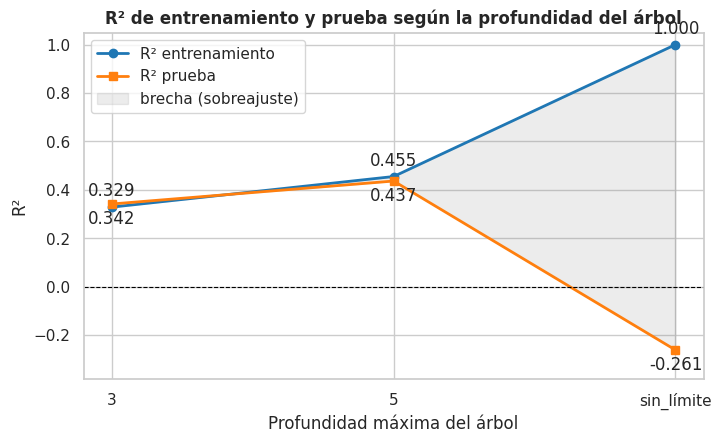

Brecha R² (train - test) por profundidad:
3            -0.0129
5             0.0186
sin_límite    1.2612
dtype: float64


In [30]:

# ---- 5.3 Curva de R2 train/test según la profundidad del árbol ----------
orden = ["3", "5", "sin_límite"]
r2_tr = [metricas_arbol[e]["train"]["R2"] for e in orden]
r2_te = [metricas_arbol[e]["test"]["R2"] for e in orden]
brecha = [t - p for t, p in zip(r2_tr, r2_te)]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(orden, r2_tr, marker="o", lw=2, label="R² entrenamiento", color="tab:blue")
ax.plot(orden, r2_te, marker="s", lw=2, label="R² prueba", color="tab:orange")
ax.fill_between(orden, r2_te, r2_tr, alpha=.15, color="gray", label="brecha (sobreajuste)")
for i, (t, p, b) in enumerate(zip(r2_tr, r2_te, brecha)):
    ax.annotate(f"{t:.3f}", (i, t), textcoords="offset points", xytext=(0, 8), ha="center")
    ax.annotate(f"{p:.3f}", (i, p), textcoords="offset points", xytext=(0, -14), ha="center")
ax.axhline(0, color="black", lw=.8, ls="--")
ax.set_ylabel("R²")
ax.set_xlabel("Profundidad máxima del árbol")
ax.set_title("R² de entrenamiento y prueba según la profundidad del árbol",
             fontsize=12, weight="bold")
ax.legend()
ax.set_ylim(min(r2_te) - 0.12, 1.05)
guardar("04_r2_vs_profundidad.png")

print("Brecha R² (train - test) por profundidad:")
print(pd.Series(brecha, index=orden).round(4))


Este código visualiza el rendimiento de los modelos de Árbol de Decisión en función de su profundidad, mostrando la curva de R² para los conjuntos de entrenamiento y prueba. Extrae los valores de R² de entrenamiento y prueba para cada profundidad (`3`, `5`, `sin_límite`) y calcula la brecha entre ellos. Genera un gráfico de líneas (`plt.plot`) donde se puede observar cómo el R² de entrenamiento aumenta con la profundidad, mientras que el R² de prueba puede disminuir en casos de sobreajuste. El área entre las curvas de R² de entrenamiento y prueba se rellena para representar visualmente la 'brecha' (sobreajuste). La función `guardar` se utiliza para almacenar la imagen del gráfico y mostrarla en pantalla.

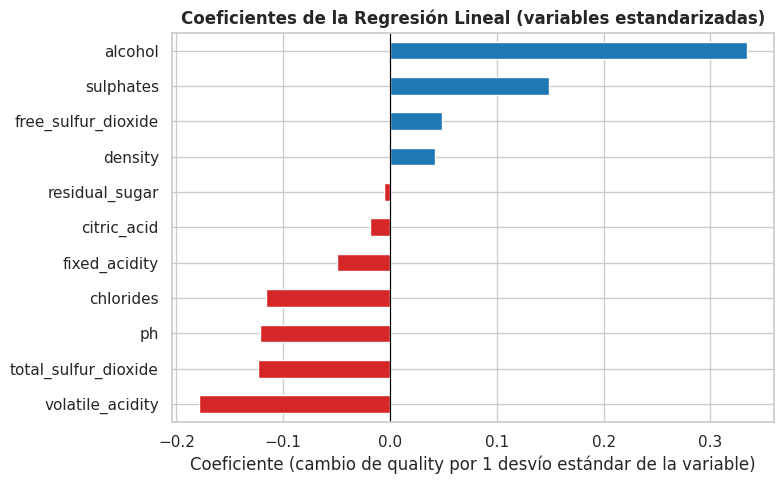

alcohol                 0.3340
sulphates               0.1485
free_sulfur_dioxide     0.0487
density                 0.0421
residual_sugar         -0.0052
citric_acid            -0.0191
fixed_acidity          -0.0497
chlorides              -0.1160
ph                     -0.1215
total_sulfur_dioxide   -0.1236
volatile_acidity       -0.1785
Name: coeficiente_std, dtype: float64


In [31]:

# ---- 5.4 Coeficientes de la Regresión Lineal ----------------------------
coef_lr = (pd.Series(reg_lin.coef_, index=X.columns, name="coeficiente_std")
           .sort_values(ascending=True))

fig, ax = plt.subplots(figsize=(8, 5))
colores = ["tab:red" if v < 0 else "tab:blue" for v in coef_lr.values]
coef_lr.plot.barh(ax=ax, color=colores)
ax.set_title("Coeficientes de la Regresión Lineal (variables estandarizadas)",
             fontsize=12, weight="bold")
ax.set_xlabel("Coeficiente (cambio de quality por 1 desvío estándar de la variable)")
ax.axvline(0, color="black", lw=.8)
plt.tight_layout()
guardar("05_coeficientes_lr.png")

print(coef_lr.sort_values(ascending=False).round(4))


Este código visualiza los coeficientes de la Regresión Lineal para entender la importancia de cada variable predictora. Los coeficientes se obtienen del modelo `reg_lin` y se organizan en una Serie de pandas, ordenados de menor a mayor. Se genera un gráfico de barras horizontales (`plot.barh`) donde el color de cada barra indica si el coeficiente es positivo (azul) o negativo (rojo). Esto permite identificar fácilmente qué variables tienen una relación positiva o negativa con la `quality` y cuál es su magnitud relativa (ya que las variables están estandarizadas). La función `guardar` se utiliza para almacenar la imagen del gráfico y mostrarla en pantalla.

Mejor árbol (mayor R2 de prueba entre 3 y 5): max_depth = 5


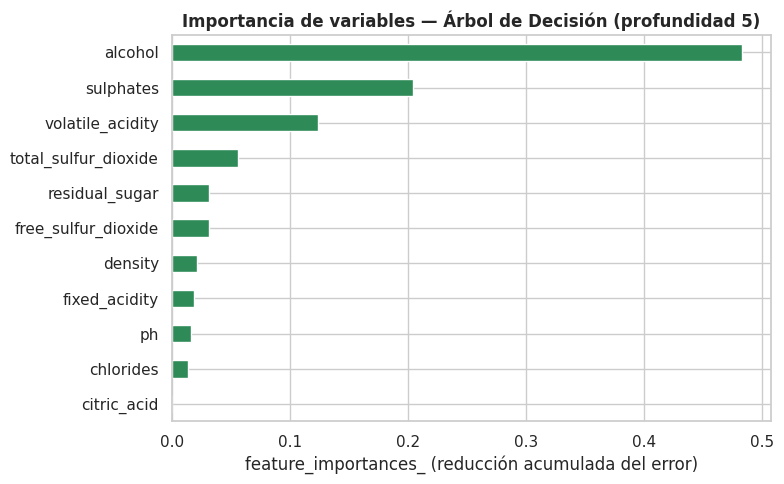

alcohol                 0.4832
sulphates               0.2044
volatile_acidity        0.1236
total_sulfur_dioxide    0.0556
residual_sugar          0.0317
free_sulfur_dioxide     0.0315
density                 0.0212
fixed_acidity           0.0190
ph                      0.0161
chlorides               0.0139
citric_acid             0.0000
Name: importancia, dtype: float64


In [32]:

# ---- 5.5 Importancia de variables del árbol elegido ---------------------
# Se descarta "sin_límite" por sobreajuste (R2 test no supera al resto) y se
# elige entre 3 y 5 la profundidad con mejor R2 de prueba.
candidatas = ["3", "5"]
mejor_prof = max(candidatas, key=lambda e: metricas_arbol[e]["test"]["R2"])
arb_mejor = arboles[mejor_prof]
print(f"Mejor árbol (mayor R2 de prueba entre 3 y 5): max_depth = {mejor_prof}")

imp = (pd.Series(arb_mejor.feature_importances_, index=X.columns, name="importancia")
       .sort_values(ascending=True))

fig, ax = plt.subplots(figsize=(8, 5))
imp.plot.barh(ax=ax, color="seagreen")
ax.set_title(f"Importancia de variables — Árbol de Decisión (profundidad {mejor_prof})",
             fontsize=12, weight="bold")
ax.set_xlabel("feature_importances_ (reducción acumulada del error)")
plt.tight_layout()
guardar("06_importancias_arbol.png")

print(imp.sort_values(ascending=False).round(4))


Este bloque de código identifica el mejor modelo de Árbol de Decisión entre las profundidades 3 y 5 (descartando 'sin_límite' por sobreajuste). Selecciona el árbol con el mayor R² en el conjunto de prueba. Luego, calcula y visualiza la importancia de las características (`feature_importances_`) de ese árbol elegido. Genera un gráfico de barras horizontales (`plot.barh`) que muestra cuánto contribuye cada variable a la reducción del error en el modelo. Esto permite comprender qué características son más relevantes para las decisiones del árbol. La función `guardar` se utiliza para almacenar la imagen del gráfico y mostrarla en pantalla.

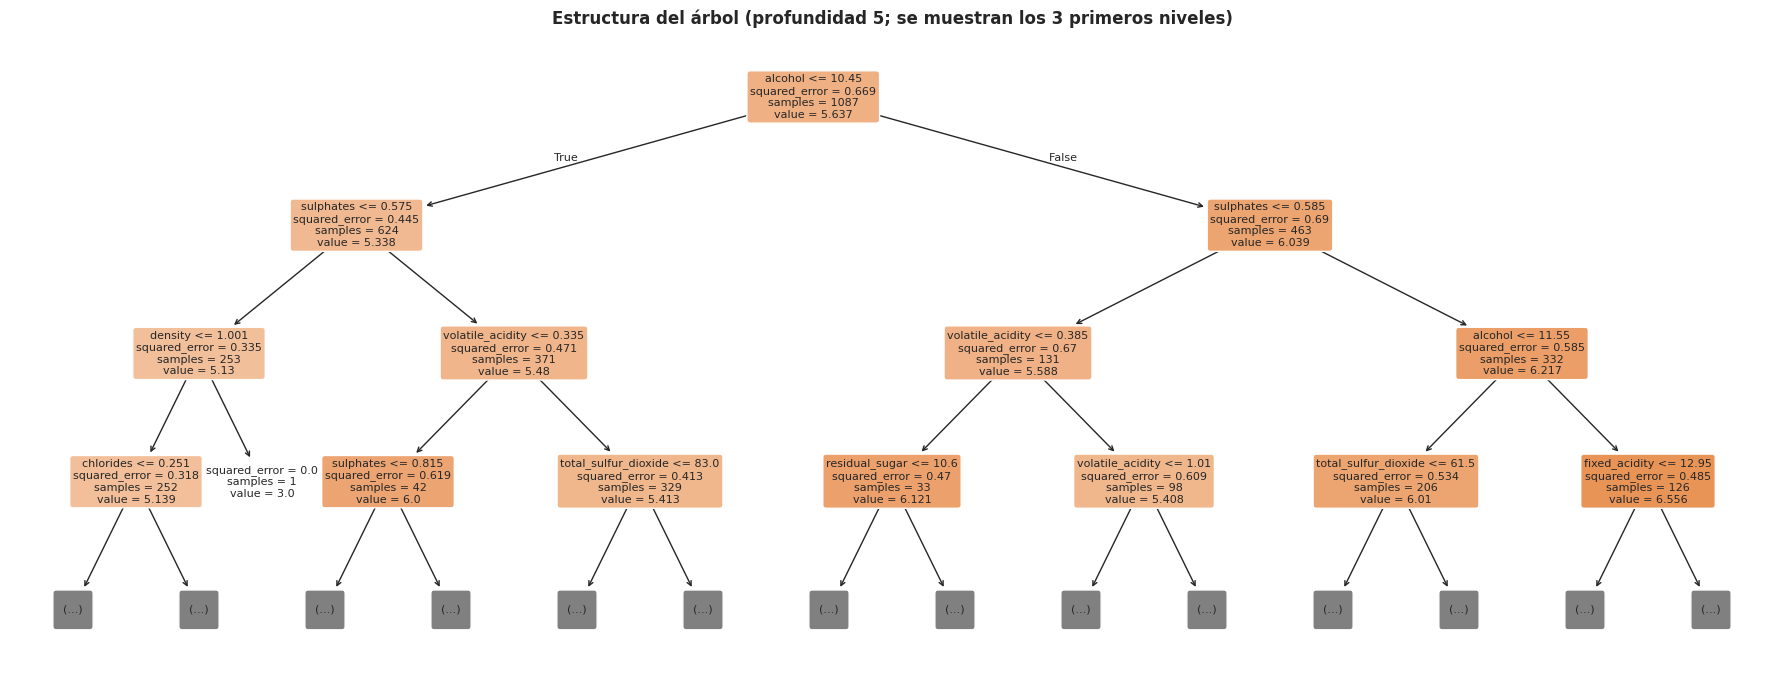

In [33]:

# ---- 5.6 Estructura del árbol elegido (referencia visual) ----------------
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(arb_mejor, feature_names=list(X.columns), filled=True, rounded=True,
          max_depth=3, fontsize=8, ax=ax)
ax.set_title(f"Estructura del árbol (profundidad {mejor_prof}; se muestran los 3 primeros niveles)",
             fontsize=12, weight="bold")
plt.tight_layout()
guardar("07_estructura_arbol.png")


Este código genera una visualización de la estructura del árbol de decisión seleccionado (`arb_mejor`). Utiliza `sklearn.tree.plot_tree` para dibujar el árbol, mostrando hasta los 3 primeros niveles de profundidad para facilitar la comprensión. Se incluyen los nombres de las características (`feature_names`) y se colorea (`filled=True`) para mejorar la claridad. Esta visualización permite entender cómo el árbol toma decisiones basadas en umbrales de las variables predictoras. La función `guardar` se utiliza para almacenar la imagen del gráfico y mostrarla en pantalla.


**Respuesta 16 — variables más relevantes en cada modelo**

- *Regresión Lineal* (coeficientes en desvíos estándar, por eso son comparables entre sí):
  los de mayor valor absoluto son **`alcohol` = +0,334** (más alcohol ⇒ vino mejor puntuado),
  **`volatile_acidity` = −0,178** (acidez volátil ⇒ sabor a vinagre, penalizado), y en menor
  medida **`sulphates` = +0,149**, `total_sulfur_dioxide` = −0,124, `ph` = −0,122 y
  `chlorides` = −0,116. El signo de los coeficientes coincide con la correlación de cada
  variable con `quality` y con el dominio del problema.
- *Árbol* (`feature_importances_`): la reducción de varianza se concentra en
  **`alcohol` = 0,483**, **`sulphates` = 0,204** y **`volatile_acidity` = 0,124**; el resto
  aporta poco (`citric_acid` = 0,000 nunca se usó para partir). Ambos modelos coinciden en
  las tres variables más relevantes: es una buena señal de consistencia.



## Etapa 6 — Selección del modelo final y conclusiones


In [34]:

# ---- 6.1 Tabla comparativa final ----------------------------------------
mejor_arbol = metricas_arbol[mejor_prof]["test"]

comparativa = pd.DataFrame({
    "Regresión Lineal": m_lr_test,
    f"Árbol (prof. {mejor_prof})": mejor_arbol,
}).T
comparativa["modelo"] = comparativa.index
comparativa = comparativa[["modelo", "MAE", "RMSE", "R2"]]
print("Tabla comparativa — métricas sobre el CONJUNTO DE PRUEBA (20 %):")
comparativa.round(4)


Tabla comparativa — métricas sobre el CONJUNTO DE PRUEBA (20 %):


,modelo,MAE,RMSE,R2
Regresión Lineal,Regresión Lineal,0.5041,0.6565,0.3915
Árbol (prof. 5),Árbol (prof. 5),0.4925,0.6317,0.4367


Este código genera una tabla comparativa final que resume las métricas de evaluación clave (MAE, RMSE, R²) para la Regresión Lineal y el mejor modelo de Árbol de Decisión (profundidad 5) en el conjunto de prueba. Crea un DataFrame `comparativa` con estas métricas, facilita la identificación del modelo con mejor rendimiento en el conjunto de datos no visto durante el entrenamiento. La tabla se imprime con los valores redondeados a cuatro decimales.

In [35]:

# ---- 6.2 Validación cruzada (5 folds): ¿la diferencia es estable? --------
# Para no depender de una única división train/test, se evalúan los modelos con
# cross-validation. En la RL el escalado se aplica DENTRO de cada fold (Pipeline),
# de modo que ningún fold "ve" información de otro (sin leakage).
from sklearn.pipeline import make_pipeline

modelos_cv = {"Regresión Lineal": make_pipeline(StandardScaler(), LinearRegression())}
for etiqueta, modelo in arboles.items():
    modelos_cv[f"Árbol (prof. {etiqueta})"] = modelo

cv_resultados = {}
for nombre, modelo in modelos_cv.items():
    scores = cross_val_score(modelo, X, y, cv=5, scoring="r2")
    mae_cv = -cross_val_score(modelo, X, y, cv=5, scoring="neg_mean_absolute_error")
    cv_resultados[nombre] = {
        "R2_promedio": scores.mean(), "R2_desvío": scores.std(),
        "MAE_promedio": mae_cv.mean(), "MAE_desvío": mae_cv.std(),
    }

tabla_cv = pd.DataFrame(cv_resultados).T
print("Validación cruzada de 5 pliegues (media ± desvío):")
tabla_cv.round(4)


Validación cruzada de 5 pliegues (media ± desvío):


,R2_promedio,R2_desvío,MAE_promedio,MAE_desvío
Regresión Lineal,0.2900,0.0852,0.5175,0.0113
Árbol (prof. 3),0.2137,0.0816,0.5457,0.0173
Árbol (prof. 5),0.1674,0.0723,0.5718,0.0249
Árbol (prof. sin_límite),-0.3980,0.1376,0.6578,0.0763


Este bloque realiza una validación cruzada (cross-validation) de 5 folds para evaluar la robustez de los modelos de Regresión Lineal y Árbol de Decisión. Para la Regresión Lineal, se utiliza un `Pipeline` para aplicar `StandardScaler` *dentro* de cada fold, evitando la fuga de información. Para los árboles, se usan los modelos previamente entrenados. Calcula el R² promedio y su desviación estándar, así como el MAE promedio y su desviación estándar, lo que permite evaluar la estabilidad del rendimiento de cada modelo más allá de una única división de entrenamiento/prueba. Los resultados se imprimen en una tabla (`tabla_cv`).

**Nota metodológica:** la validación cruzada se corrió sobre **todo** el dataset (incluye el 20 % de prueba) porque su propósito aquí es comparar la *estabilidad relativa* entre modelos, no estimar el error final; el rendimiento reportado del modelo elegido es el del conjunto de prueba. Para una estimación estricta del error, la CV debería aplicarse sólo sobre el conjunto de entrenamiento.

In [36]:

# ---- 6.3 Tabla comparativa final: prueba + validación cruzada ------------
final = pd.DataFrame({
    "MAE_test": [m_lr_test["MAE"], mejor_arbol["MAE"]],
    "RMSE_test": [m_lr_test["RMSE"], mejor_arbol["RMSE"]],
    "R2_test": [m_lr_test["R2"], mejor_arbol["R2"]],
    "brecha_R2_train_test": [m_lr_train["R2"] - m_lr_test["R2"],
                             metricas_arbol[mejor_prof]["train"]["R2"] - mejor_arbol["R2"]],
    "R2_validacion_cruzada_5folds": [cv_resultados["Regresión Lineal"]["R2_promedio"],
                                     cv_resultados[f"Árbol (prof. {mejor_prof})"]["R2_promedio"]],
    "R2_cv_desvío": [cv_resultados["Regresión Lineal"]["R2_desvío"],
                     cv_resultados[f"Árbol (prof. {mejor_prof})"]["R2_desvío"]],
}, index=["Regresión Lineal", f"Árbol (prof. {mejor_prof})"])

print("TABLA COMPARATIVA FINAL (Etapa 6):")
final.round(4)


TABLA COMPARATIVA FINAL (Etapa 6):


,MAE_test,RMSE_test,R2_test,brecha_R2_train_test,R2_validacion_cruzada_5folds,R2_cv_desvío
Regresión Lineal,0.5041,0.6565,0.3915,-0.0395,0.2900,0.0852
Árbol (prof. 5),0.4925,0.6317,0.4367,0.0186,0.1674,0.0723


Este código crea una tabla comparativa final que combina las métricas de rendimiento en el conjunto de prueba con los resultados de la validación cruzada. Para cada modelo (Regresión Lineal y Árbol de Decisión con la mejor profundidad), incluye MAE, RMSE y R² del test, la brecha R² (entrenamiento - test), y el R² promedio con su desviación estándar obtenidos de la validación cruzada de 5 folds. Esta tabla (`final`) ofrece una visión consolidada y robusta del rendimiento de ambos modelos, facilitando la toma de decisiones sobre cuál es el mejor. La tabla se imprime con los valores redondeados a cuatro decimales.


### Selección del modelo final

Criterios utilizados (no sólo las métricas del split de prueba):

1. **Métricas en prueba:** el Árbol (prof. 5) gana levemente en las tres métricas
   (MAE 0,4925 vs 0,5041; RMSE 0,6317 vs 0,6565; R² 0,4367 vs 0,3915).
2. **Robustez (validación cruzada de 5 pliegues, usada aquí como medida de robustez comparativa y no como estimación final del error):** la situación se invierte y con claridad —
   la Regresión Lineal obtiene **R² = 0,290 ± 0,085** contra **0,167 ± 0,072** del árbol.
   Es decir, promediando sobre 5 particiones distintas de los datos, el árbol no repite su
   victoria: su ventaja en el split único puntual es una particularidad de esa división
   (alta varianza, propio de los árboles), no una ventaja estable.
3. **Interpretabilidad:** la Regresión Lineal entrega un coeficiente por variable con signo
   y magnitud explicables en términos del dominio (p. ej. `alcohol` +0,334 y
   `volatile_acidity` −0,178 por desvío estándar); el árbol es un conjunto de umbrales
   difíciles de comunicar al laboratorio.
4. **Simplicidad / parsimonia:** un único modelo lineal con 11 coeficientes frente a un
   árbol con decenas de nodos, con el riesgo de sobreajuste que eso implica (visible al
   subir la profundidad: R² test −0,261 sin límite).

**Modelo final: Regresión Lineal Múltiple.** Se elige porque su desempeño es mejor cuando se
lo evalúa de forma repetida (CV), su brecha train/test es mínima de hecho negativa
(R² train 0,3520 < R² test 0,3915 ⇒ el modelo no se sobreajusta) y es interpretable.
El Árbol de Decisión (prof. 5) queda como modelo alternativo válido —incluso gana en el split
de prueba puntual—, pero su mayor varianza y menor interpretabilidad lo dejan en segundo lugar.
Con más datos o una búsqueda de hiperparámetros con validación (p. ej. `max_depth` junto con
`min_samples_leaf`), el árbol podría acercarse o superar de forma estable a la regresión lineal.



## 5. Preguntas de análisis



**20. ¿Por qué conviene eliminar los duplicados exactos antes de dividir en train/test?**

Porque un duplicado es la misma observación repetida. Si se elimina *después* del split, es
muy probable que una copia quede en entrenamiento y otra en prueba: el modelo "memorizó" la
respuesta y evalúa sobre un dato que ya vio (**data leakage**). Las métricas de prueba quedan
artificialmente optimistas y no reflejan el rendimiento real sobre muestras nuevas. Eliminarlos
antes garantiza que la división sea honesta, que las muestras sean independientes y que la
distribución del set de prueba represente a datos verdaderamente nuevos.

**21. ¿Conviene eliminar los outliers detectados por IQR?**

**No: conviene conservarlos.** (i) Dominio: los valores extremos de azúcar residual, cloruros,
sulfatos o dióxido de azufre son características reales del vino, no errores de carga; borrarlos
sesgaría la muestra hacia el vino "promedio" y el modelo dejaría de aprender exactamente los
vinos atípicos. (ii) Robustez: el Árbol de Decisión es insensible a la magnitud de los extremos
(sólo usa cortes) y la Regresión Lineal, aunque es más sensible, se beneficia de no perder el
25 % de las filas (las que tienen al menos un outlier). (iii) Costo: eliminar filas con al menos un outlier en alguna variable
implica perder demasiados datos; cualquier transformación alteraría las unidades originales.

**22. ¿Por qué escalar para interpretar la Regresión Lineal y no para el Árbol?**

La Regresión Lineal estima un coeficiente por variable: si las variables están en escalas
distintas (g/dm³, mg/dm³, pH), el tamaño del coeficiente refleja la unidad y no la importancia
real. Con `StandardScaler`, un coeficiente significa "cambio de `quality` por 1 desvío
estándar", lo que hace **comparables** los coeficientes entre sí. El Árbol, en cambio, sólo
busca el mejor umbral `x ≤ t` para partir; una transformación lineal monótona (como estandarizar)
corresponde los umbrales pero **no cambia las particiones ni el árbol resultante**, por lo que
escalar no aporta nada.

**23. ¿Qué significa un R² de prueba negativo con R² de entrenamiento ≈ 1?**

`R² < 0` significa que el modelo predice **peor que simplemente usar la media** de `y` como
predicción constante (la suma de errores del modelo supera a la variabilidad total de los datos).
Combinado con `R²(train) ≈ 1`, es la evidencia de **sobreajuste extremo**: el árbol sin límite de
profundidad memorizó cada registro (varianza cero en train) y no generaliza absolutamente nada
ante datos nuevos. Es el caso más claro de que crecer sin control de profundidad destruye la
capacidad predictiva.



**24. Repetición de la comparación final SIN eliminar los duplicados (Etapa 2).**

Se reconstruye todo el pipeline usando el dataset con duplicados (mismo split, mismo escalado,
mismos modelos) para medir cuánto cambia la conclusión.


In [37]:

# ---- 24. Experimento control: dataset CON duplicados ---------------------
df_con_dup = df_sin_nulos.copy()   # nulos ausentes y nombres estandarizados, pero CON duplicados

X_dup = df_con_dup.drop(columns=["quality"])
y_dup = df_con_dup["quality"]

Xtr_d, Xte_d, ytr_d, yte_d = train_test_split(
    X_dup, y_dup, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

sc_d = StandardScaler()
Xtr_d_esc = sc_d.fit_transform(Xtr_d)
Xte_d_esc = sc_d.transform(Xte_d)

# Regresión Lineal
rl_dup = LinearRegression().fit(Xtr_d_esc, ytr_d)
m_lr_dup = metricas(yte_d, rl_dup.predict(Xte_d_esc))

# Árboles (mismas profundidades)
m_arb_dup = {}
for prof in PROFUNDIDADES:
    etiqueta = "sin_límite" if prof is None else str(prof)
    a = DecisionTreeRegressor(max_depth=prof, random_state=RANDOM_STATE).fit(Xtr_d, ytr_d)
    m_arb_dup[etiqueta] = {"train": metricas(ytr_d, a.predict(Xtr_d)),
                           "test": metricas(yte_d, a.predict(Xte_d))}

# ¿Aparecieron duplicados entre train y test? (data leakage)
dup_en_teste = Xte_d.duplicated().sum()
print(f"Filas de test que también existen en train (leakage): {int(dup_en_teste)} "
      f"({100*dup_en_teste/len(Xte_d):.1f} % del set de prueba)")

# Validación cruzada del mismo experimento (5 folds), para comparar perros y gatos
cv_dup = {}
for nombre, modelo in [("Regresión Lineal", make_pipeline(StandardScaler(), LinearRegression())),
                       (f"Árbol (prof. {mejor_prof})",
                        DecisionTreeRegressor(max_depth=int(mejor_prof), random_state=RANDOM_STATE))]:
    sc = cross_val_score(modelo, X_dup, y_dup, cv=5, scoring="r2")
    cv_dup[nombre] = {"R2_promedio": sc.mean(), "R2_desvío": sc.std()}

print("\nValidación cruzada (5 folds) CON duplicados:")
print(pd.DataFrame(cv_dup).T.round(4))


Filas de test que también existen en train (leakage): 10 (3.1 % del set de prueba)

Validación cruzada (5 folds) CON duplicados:
                  R2_promedio  R2_desvío
Regresión Lineal       0.2900     0.0845
Árbol (prof. 5)        0.1993     0.0673


Este bloque de código realiza un experimento de control replicando el pipeline *sin eliminar los duplicados* del dataset original. Prepara los datos (`X_dup`, `y_dup`), los divide en entrenamiento y prueba (`Xtr_d`, `Xte_d`, `ytr_d`, `yte_d`), escala las variables para la Regresión Lineal, entrena ambos tipos de modelos y calcula sus métricas. También verifica la presencia de duplicados en el conjunto de prueba que pudieran haber aparecido en entrenamiento (`data leakage`). Finalmente, realiza una validación cruzada con este dataset con duplicados para comparar la estabilidad del rendimiento de los modelos bajo esta condición.

In [38]:

# ---- 24.2 Comparación de las dos corridas --------------------------------
def fila(nombre, m):
    return {"modelo": nombre, "MAE": m["MAE"], "RMSE": m["RMSE"], "R2": m["R2"]}

comparacion = pd.DataFrame([
    fila("RL — con duplicados (Etapa 2 NO aplicada)", m_lr_dup),
    fila("RL — sin duplicados (pipeline correcto)", m_lr_test),
    fila(f"Árbol prof. {mejor_prof} — con duplicados", m_arb_dup[mejor_prof]["test"]),
    fila(f"Árbol prof. {mejor_prof} — sin duplicados", mejor_arbol),
])
print("Comparación de métricas sobre el conjunto de prueba:")
comparacion.round(4)


Comparación de métricas sobre el conjunto de prueba:


,modelo,MAE,RMSE,R2
0,RL — con duplicados (Etapa 2 NO aplicada),0.5035,0.6245,0.4032
1,RL — sin duplicados (pipeline correcto),0.5041,0.6565,0.3915
2,Árbol prof. 5 — con duplicados,0.4964,0.6584,0.3366
3,Árbol prof. 5 — sin duplicados,0.4925,0.6317,0.4367


Este código compara las métricas de evaluación (MAE, RMSE, R²) obtenidas en dos escenarios: con y sin la eliminación de filas duplicadas en la Etapa 2. Crea un DataFrame `comparacion` que agrupa las métricas de la Regresión Lineal y del Árbol de Decisión (profundidad 5) para ambos casos. Esta tabla permite observar el impacto de la decisión de limpieza de duplicados en el rendimiento reportado por los modelos, destacando cómo el 'data leakage' puede inflar artificialmente las métricas. La tabla se imprime con los valores redondeados a cuatro decimales.


**Respuesta 24.** La conclusión **sí cambia**:

| Escenario | Regresión Lineal (R² / RMSE test) | Árbol prof. 5 (R² / RMSE test) | Mejor modelo |
|---|---|---|---|
| **Sin eliminar duplicados** (Etapa 2 no aplicada) | 0,403 / 0,625 | 0,337 / 0,658 | **Regresión Lineal** |
| **Eliminando duplicados** (pipeline correcto) | 0,392 / 0,657 | 0,437 / 0,632 | **Árbol de Decisión (prof. 5)** |

Además, en el escenario con duplicados **10 de las 320 filas de prueba (3,1 %) estaban
también en entrenamiento**: es el *data leakage* que se intenta evitar. Se nota en que el
árbol sin límite deja de tener R² de prueba negativo (pasa de −0,261 a +0,072) aunque siga sin
generalizar bien.

Con **validación cruzada de 5 pliegues** el orden sí es estable: Regresión Lineal 0,290 contra
0,199 del árbol (con duplicados) y 0,290 contra 0,167 (sin duplicados). Es decir, los
duplicados inflan el desempeño del árbol (0,167 → 0,199) pero no alcanzan para voltear el
resultado cuando se promedia en varios pliegues.

**Qué demuestra esto:** si la Etapa 6 se resuelve sólo con la tabla del conjunto de prueba
(paso 17 del enunciado), la respuesta a "¿cuál es el mejor modelo?" depende de una decisión
tomada en la **Etapa 2**: cambiar el tamaño de la muestra (1.599 → 1.359 filas) modifica la
composición del split y eso alcanza para invertir el orden entre los dos algoritmos. Las
decisiones tempranas del KDD contaminan todos los resultados posteriores: por eso cada una
debe justificarse (limpieza, duplicados, outliers) y por eso conviene apoyar la elección en
validación cruzada, que en este caso mantiene la Regresión Lineal como modelo final en los
dos escenarios.



### Conclusiones generales

Se documentó y justificó cada decisión de las 6 etapas del proceso KDD: selección del dataset
público adecuado, limpieza (sin nulos; 240 duplicados eliminados antes del split; outliers IQR
conservados por dominio y robustez, con 25,02 % de las filas afectadas), transformación
(split 80/20 con semilla fija; escalado sólo para el modelo lineal), minería (Regresión Lineal
+ Árbol con profundidades 3, 5 y sin límite), evaluación (MAE, RMSE, R², brecha train/test,
coeficientes e importancias) y selección final.

**Modelo final elegido: la Regresión Lineal Múltiple**, por su mejor desempeño promedio en
validación cruzada (R² 0,290 vs 0,167 del árbol), su brecha train/test mínima y su completa
interpretabilidad, frente a un árbol que sólo gana en el split de prueba puntual.
